# Sub-etapa 1.4 · Evaluación y selección del modelo

**Objetivo (plan del proyecto):** comparar exactitud, F1-score y AUC con validación cruzada y **justificar la selección del mejor modelo para pasar a la Etapa 2**.

Este notebook no vuelve a entrenar lo que ya se hizo: junta los resultados de los notebooks 03 y 04 (las tres opciones de `DATOS`), los compara con una prueba estadística adecuada para validación cruzada, evalúa unos pocos modelos nuevos que se decidieron **antes** de mirar los resultados, y elige el modelo final con criterios escritos de antemano.

**Productos:**

| Archivo | Contenido |
|---|---|
| `resultados/tabla_comparativa.csv` | **Tabla comparativa de métricas**: todos los modelos y fuentes de datos (media ± desviación e intervalo de confianza del AUC) |
| `resultados/comparacion_estadistica.csv` | Cada modelo comparado con el mejor de su fuente de datos (prueba t corregida + Holm) |
| `resultados/metricas_por_particion_1_4.csv` | Métricas de los modelos nuevos en cada partición |
| `modelos/modelo_final.joblib`, `modelos/info_modelo_final.json` | **Modelo seleccionado** para la Etapa 2, con su umbral y su justificación |
| `figuras/seleccion_*.png` | Gráficos para el informe |

**Antes de ejecutarlo:** el notebook 03 y el 04 deben estar ejecutados con las tres opciones de `DATOS`, y el 01b, ejecutado.

## Decisiones tomadas antes de ver los resultados de esta sub-etapa

Con pocas personas, si se prueban muchas variantes y se reporta la que mejor resulta, el resultado sale optimista por puro azar. Para evitarlo, todo lo que se evalúa aquí quedó fijado de antemano:

1. **Prueba estadística:** prueba t pareada con la corrección de Nadeau y Bengio (2003) para validación cruzada repetida, y corrección de Holm por comparar varios modelos.
2. **Modelos nuevos con laboratorio** (con las mismas particiones del notebook 03):
   * *Una variable elegida dentro de cada partición:* versión honesta de "solo frecuencia dominante", que en el notebook 03 se eligió mirando a todas las personas.
   * *Tres variables elegidas dentro de cada partición* (regresión logística).
   * *Variables medibles con cámara* (regresión logística y Random Forest): solo las variables de ritmo y de tiempo, que se pueden obtener desde un video en la Etapa 2.
3. **Dos variantes de vida diaria:** solo tramos largos (≥ 60 s) y variabilidad entre tramos de una misma persona.
4. **Criterios de selección** (sección 7): el modelo debe funcionar con datos que la Etapa 2 pueda obtener, no ser significativamente peor que el mejor, y ser lo más simple posible.

## 1. Configuración

In [1]:
import json
import platform
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import stats
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESADOS = RAIZ / "datos" / "procesados"
TRAMOS = PROCESADOS / "vida_diaria" / "tramos"
MODELOS = RAIZ / "modelos"
RESULTADOS = RAIZ / "resultados"
FIGURAS = RAIZ / "figuras"
for carpeta in (MODELOS, RESULTADOS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

# --- Validación: igual que los notebooks 03 y 04 ----------------------------------
SEMILLA = 42
N_PARTICIONES = 5
N_REPETICIONES = 10
FRACCION = 1 / (N_PARTICIONES - 1)   # personas de prueba / personas de entrenamiento (para la corrección)

# --- Decisiones fijadas de antemano -----------------------------------------------
# Variables que se pueden medir con una cámara: ritmo y tiempos de la marcha (no dependen de la unidad del sensor)
VARIABLES_CAMARA = ["cadencia_pasos_min", "tiempo_paso_s", "cv_tiempo_paso_pct", "tiempo_zancada_s",
                    "cv_tiempo_zancada_pct", "regularidad_paso", "regularidad_zancada", "simetria",
                    "frec_dominante_hz"]
MIN_TRAMO_LARGO_S = 60         # variante de vida diaria: solo tramos de al menos 60 s
SENSIBILIDAD_OBJETIVO = 0.80   # para una herramienta de tamizaje, importa no dejar pasar a quien cae
ALFA = 0.05

METRICAS = ["exactitud", "sensibilidad", "especificidad", "f1", "auc"]
FUENTES = {"laboratorio": "", "vida_diaria": "_vida_diaria", "combinado": "_combinado"}
COLORES = {"laboratorio": "#2a78d6", "vida_diaria": "#eb6834", "combinado": "#1baf7a"}
NOMBRE_FUENTE = {"laboratorio": "Laboratorio", "vida_diaria": "Vida diaria", "combinado": "Combinado"}

np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

Python 3.14.6 | numpy 2.4.6 | pandas 3.0.3 | scipy 1.18.0 | scikit-learn 1.9.0 | matplotlib 3.11.0


## 2. Resultados de los notebooks 03 y 04

Se cargan las métricas de cada partición de todos los modelos y de las tres fuentes de datos. Random Forest, XGBoost y las referencias tienen 50 pruebas; la LSTM, 15 (las mismas 15 primeras particiones).

In [2]:
def cargar(archivo, fuente):
    if not archivo.exists():
        return pd.DataFrame()
    t = pd.read_csv(archivo)
    t["particion"] = t.groupby("modelo").cumcount() + 1
    t["fuente"] = fuente
    return t[["fuente", "modelo", "particion"] + METRICAS]


partes, faltan = [], []
for fuente, sufijo in FUENTES.items():
    for archivo in (RESULTADOS / f"metricas_por_particion{sufijo}.csv",
                    RESULTADOS / f"metricas_lstm_por_particion{sufijo}.csv"):
        t = cargar(archivo, fuente)
        (partes if len(t) else faltan).append(t if len(t) else archivo.name)
todas = pd.concat(partes, ignore_index=True)
# La referencia de una variable (elegida en el EDA) cambia de nombre según la fuente (p. ej. frec_dominante_hz_lab)
todas["modelo"] = (todas["modelo"].str.replace(r"^Solo frec_dominante\S*$", "Solo frecuencia dominante", regex=True)
                   .str.replace(r"_(lab|vd)$", "", regex=True))
# Esa referencia se eligió mirando a todas las personas, así que su AUC puede estar inflado (ver sección 4)
REFERENCIA_EDA = [m for m in todas["modelo"].unique() if m.startswith("Solo ") and m != "Solo TUG"]
if faltan:
    print("Atención, no se encontraron:", ", ".join(faltan), "(ejecuta el notebook que corresponde)")
print(todas.groupby(["fuente", "modelo"]).size().unstack(0).fillna(0).astype(int))

fuente                     combinado  laboratorio  vida_diaria
modelo                                                        
LSTM                              15           15           15
Random Forest                     50           50           50
Sin modelo                        50           50           50
Solo TUG                          50           50           50
Solo frecuencia dominante         50           50           50
XGBoost                           50           50           50


## 3. Cómo comparar modelos evaluados con validación cruzada

Las pruebas de una validación cruzada **no son independientes**: dos particiones comparten la mayor parte de sus personas de entrenamiento. Una prueba t común las trataría como independientes y encontraría diferencias "significativas" que no lo son. Nadeau y Bengio (2003) propusieron corregir la varianza agregando la fracción de personas de prueba sobre las de entrenamiento:

$$t = \frac{\bar d}{\sqrt{\left(\frac{1}{J} + \frac{n_{prueba}}{n_{entrenamiento}}\right) s_d^2}}$$

donde $\bar d$ y $s_d^2$ son la media y la varianza de las diferencias de AUC entre dos modelos en las mismas $J$ pruebas. Con la misma corrección se calcula un **intervalo de confianza del 95 %** para el AUC de cada modelo.

Los modelos de **distintas fuentes de datos no se pueden comparar de a pares**, porque no tienen exactamente las mismas personas; para ellos se comparan los intervalos de confianza.

In [3]:
def prueba_t_corregida(a, b):
    # Compara dos modelos evaluados en las mismas pruebas (a y b: AUC por prueba). Devuelve (diferencia media, p)
    d = np.asarray(a) - np.asarray(b)
    J = len(d)
    var = np.var(d, ddof=1)
    if var == 0:
        return d.mean(), 1.0 if d.mean() == 0 else 0.0
    t = d.mean() / np.sqrt((1 / J + FRACCION) * var)
    return d.mean(), 2 * stats.t.sf(abs(t), df=J - 1)


def intervalo(x):
    # Intervalo de confianza del 95 % de la media, con la varianza corregida
    x = np.asarray(x)
    J = len(x)
    e = stats.t.ppf(0.975, J - 1) * np.sqrt((1 / J + FRACCION) * np.var(x, ddof=1))
    return x.mean() - e, x.mean() + e


def holm(p):
    p = np.asarray(p, dtype=float)
    orden = np.argsort(p)
    ajustado, acumulado = np.empty_like(p), 0.0
    for k, i in enumerate(orden):
        acumulado = max(acumulado, min(1.0, (len(p) - k) * p[i]))
        ajustado[i] = acumulado
    return ajustado


def metricas(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    return {"exactitud": accuracy_score(y, pred), "sensibilidad": recall_score(y, pred, zero_division=0),
            "especificidad": recall_score(y, pred, pos_label=0, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0), "auc": roc_auc_score(y, prob)}

## 4. Modelos nuevos con las caminatas de laboratorio

Se usan **exactamente las mismas 50 particiones** del notebook 03 (misma tabla, mismo orden de personas y misma semilla), para poder compararlos de a pares con Random Forest, XGBoost y las referencias.

La selección de variables (`SelectKBest`) va **dentro** del `pipeline`: en cada partición, las variables se eligen solo con las personas de entrenamiento. Así se evita el sesgo de elegirlas mirando a todos, que es lo que ocurrió con "solo frecuencia dominante" en el notebook 03.

In [4]:
lab = pd.read_csv(PROCESADOS / "labwalks_modelo.csv")
completo = pd.read_csv(PROCESADOS / "labwalks_variables.csv")
VARIABLES_LAB = [c for c in lab.columns if c not in ("registro", "grupo", "cae")]
camara = lab[["registro"]].merge(completo[["registro"] + VARIABLES_CAMARA], on="registro", how="left")
assert (camara["registro"] == lab["registro"]).all()
y_lab = lab["cae"].astype(int).to_numpy()
X_lab = lab[VARIABLES_LAB]
X_cam = camara[VARIABLES_CAMARA]
print(f"Laboratorio: {len(lab)} personas | {len(VARIABLES_LAB)} variables del modelo | "
      f"{len(VARIABLES_CAMARA)} variables medibles con cámara")


def logistica(k=None):
    pasos = [SimpleImputer(strategy="median"), StandardScaler()]
    if k is not None:
        pasos.append(SelectKBest(f_classif, k=k))
    return make_pipeline(*pasos, LogisticRegression(max_iter=1000))


def bosque():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=500, min_samples_leaf=2, class_weight="balanced",
                                                random_state=SEMILLA, n_jobs=-1))


def evaluar(nombre, modelo, X, y, fuente):
    # Validación cruzada a mano: así se puede guardar qué variables eligió el modelo en cada partición
    validacion = RepeatedStratifiedKFold(n_splits=N_PARTICIONES, n_repeats=N_REPETICIONES, random_state=SEMILLA)
    filas, elegidas = [], []
    for j, (ent, pru) in enumerate(validacion.split(X, y), start=1):
        m = clone(modelo).fit(X.iloc[ent], y[ent])
        filas.append({"fuente": fuente, "modelo": nombre, "particion": j,
                      **metricas(y[pru], m.predict_proba(X.iloc[pru])[:, 1])})
        if "selectkbest" in m.named_steps:
            elegidas += list(X.columns[m.named_steps["selectkbest"].get_support()])
    return pd.DataFrame(filas), pd.Series(elegidas, dtype=str).value_counts()


nuevos, conteos = [], {}
for nombre, modelo, X in [
    ("1 variable elegida en cada partición", logistica(k=1), X_lab),
    ("3 variables elegidas en cada partición", logistica(k=3), X_lab),
    ("1 variable de cámara elegida en cada partición", logistica(k=1), X_cam),
    ("Logística, variables de cámara", logistica(), X_cam),
    ("Random Forest, variables de cámara", bosque(), X_cam),
]:
    r, c = evaluar(nombre, modelo, X, y_lab, "laboratorio")
    nuevos.append(r)
    conteos[nombre] = c
    print(f"{nombre}: AUC {r['auc'].mean():.3f} ± {r['auc'].std():.3f}")

Laboratorio: 72 personas | 14 variables del modelo | 9 variables medibles con cámara
1 variable elegida en cada partición: AUC 0.623 ± 0.167
3 variables elegidas en cada partición: AUC 0.649 ± 0.152
1 variable de cámara elegida en cada partición: AUC 0.724 ± 0.149
Logística, variables de cámara: AUC 0.633 ± 0.149
Random Forest, variables de cámara: AUC 0.662 ± 0.137


1 variable elegida en cada partición: la más elegida fue frec_dominante_hz (28 de 50 particiones)
3 variables elegidas en cada partición: la más elegida fue frec_dominante_hz (48 de 50 particiones, contando las 3 de cada una)
1 variable de cámara elegida en cada partición: la más elegida fue frec_dominante_hz (46 de 50 particiones)


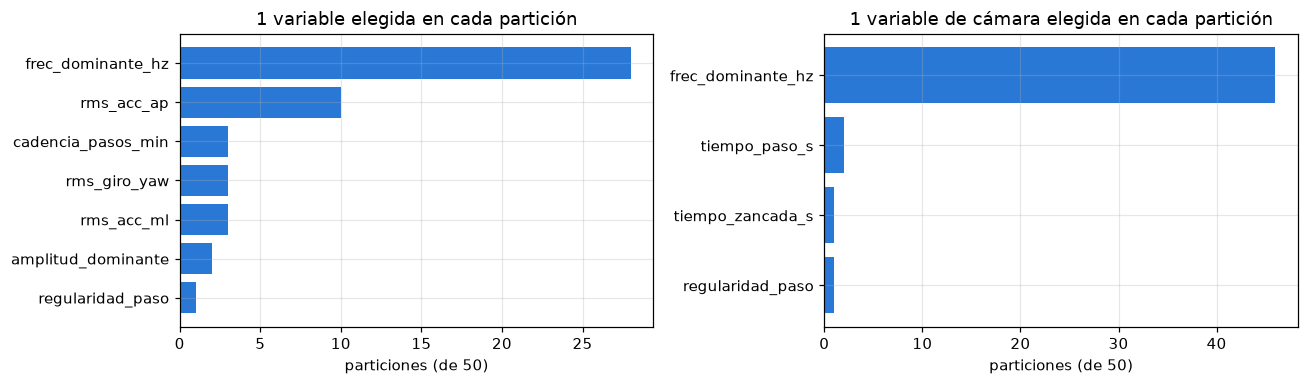

In [5]:
# ¿Qué variable elige el modelo de una sola variable en cada una de las 50 particiones?
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6))
for eje, nombre in zip(ejes, ["1 variable elegida en cada partición", "1 variable de cámara elegida en cada partición"]):
    c = conteos[nombre].sort_values()
    eje.barh(c.index, c.values, color="#2a78d6")
    eje.set(title=nombre, xlabel="particiones (de 50)")
fig.tight_layout()
fig.savefig(FIGURAS / "seleccion_variables_elegidas.png", dpi=150)
for nombre in conteos:
    if len(conteos[nombre]):
        v, n = conteos[nombre].index[0], conteos[nombre].iloc[0]
        print(f"{nombre}: la más elegida fue {v} ({n} de {N_PARTICIONES * N_REPETICIONES} particiones"
              f"{'' if nombre.startswith('1 ') else ', contando las 3 de cada una'})")

## 5. Variantes de vida diaria

Dos ideas, fijadas de antemano, para aprovechar mejor los registros de 3 días (se usan las mismas 70 personas y las mismas particiones de `DATOS = "vida_diaria"` en el notebook 03):

* **Solo tramos largos:** mediana de cada variable usando solo los tramos de al menos 60 s, en los que la marcha es más estable. Si una persona tiene menos de 3 tramos largos, el valor queda vacío y se completa con la mediana de entrenamiento.
* **Variabilidad entre tramos:** además de la mediana, cuánto cambia cada variable de un tramo a otro en la misma persona (rango intercuartílico relativo). La hipótesis es que la mediana borra justamente la variabilidad que podría distinguir a quienes caen.

Cada variante se evalúa con regresión logística (3 variables elegidas en cada partición) y con Random Forest.

In [6]:
vd = pd.read_csv(PROCESADOS / "vida_diaria_modelo.csv") if (PROCESADOS / "vida_diaria_modelo.csv").exists() else None
archivos_tramos = sorted(TRAMOS.glob("*.csv")) if TRAMOS.exists() else []
if vd is None or not archivos_tramos:
    print("No hay datos de vida diaria; se omite esta sección (ejecuta el notebook 01b).")
else:
    tablas = [pd.read_csv(p) for p in archivos_tramos]
    tramos = pd.concat([t for t in tablas if not t.empty], ignore_index=True)
    tramos = tramos[tramos["valido"] == True]
    BASE_VD = ["cadencia_pasos_min", "cv_tiempo_paso_pct", "cv_tiempo_zancada_pct", "regularidad_paso",
               "simetria", "frec_dominante_hz", "amplitud_dominante", "rms_acc_v"]
    BASE_VD = [v for v in BASE_VD if v in tramos.columns]

    largos = tramos[tramos["duracion_s"] >= MIN_TRAMO_LARGO_S]
    n_largos = largos.groupby("registro").size()
    med_largos = largos.groupby("registro")[BASE_VD].median()
    med_largos[n_largos.reindex(med_largos.index).fillna(0) < 3] = np.nan

    def iqr_relativo(x):
        q1, q2, q3 = np.percentile(x, [25, 50, 75])
        return (q3 - q1) / abs(q2) if q2 != 0 else np.nan

    variab = tramos.groupby("registro")[BASE_VD].agg(iqr_relativo).add_prefix("variab_")
    medianas = tramos.groupby("registro")[BASE_VD].median()

    orden = vd[["registro"]]
    X_largos = orden.merge(med_largos, left_on="registro", right_index=True, how="left")[BASE_VD]
    X_variab = orden.merge(pd.concat([medianas, variab], axis=1), left_on="registro", right_index=True,
                           how="left").drop(columns="registro")
    y_vd = vd["cae"].astype(int).to_numpy()
    print(f"Vida diaria: {len(vd)} personas | con al menos 3 tramos largos: {int(X_largos.notna().all(axis=1).sum())}")
    for nombre, modelo, X in [
        ("Tramos largos, 3 variables elegidas", logistica(k=3), X_largos),
        ("Tramos largos, Random Forest", bosque(), X_largos),
        ("Variabilidad entre tramos, 3 variables elegidas", logistica(k=3), X_variab),
        ("Variabilidad entre tramos, Random Forest", bosque(), X_variab),
    ]:
        r, c = evaluar(nombre, modelo, X, y_vd, "vida_diaria")
        nuevos.append(r)
        conteos[nombre] = c
        print(f"{nombre}: AUC {r['auc'].mean():.3f} ± {r['auc'].std():.3f}")

nuevos = pd.concat(nuevos, ignore_index=True)
nuevos.to_csv(RESULTADOS / "metricas_por_particion_1_4.csv", index=False)

Vida diaria: 70 personas | con al menos 3 tramos largos: 66
Tramos largos, 3 variables elegidas: AUC 0.590 ± 0.169
Tramos largos, Random Forest: AUC 0.509 ± 0.159
Variabilidad entre tramos, 3 variables elegidas: AUC 0.463 ± 0.150
Variabilidad entre tramos, Random Forest: AUC 0.640 ± 0.126


## 6. Tabla comparativa de métricas

Producto principal de la sub-etapa: todos los modelos, con las tres fuentes de datos. Se muestra la media ± desviación estándar de cada métrica y el intervalo de confianza del 95 % del AUC (con la varianza corregida).

In [7]:
todo = pd.concat([todas, nuevos], ignore_index=True)
filas = []
for (fuente, modelo), g in todo.groupby(["fuente", "modelo"], sort=False):
    fila = {"fuente": fuente, "modelo": modelo, "pruebas": len(g)}
    for m in METRICAS:
        fila[m] = f"{g[m].mean():.2f} ± {g[m].std():.2f}"
    a, b = intervalo(g["auc"])
    fila.update({"auc_media": g["auc"].mean(), "auc_ic95": f"[{a:.2f}; {b:.2f}]", "ic_inf": a, "ic_sup": b})
    filas.append(fila)
tabla = pd.DataFrame(filas)
tabla["fuente"] = pd.Categorical(tabla["fuente"], list(FUENTES))
tabla = tabla.sort_values(["fuente", "auc_media"], ascending=[True, False]).reset_index(drop=True)
tabla.drop(columns=["ic_inf", "ic_sup"]).to_csv(RESULTADOS / "tabla_comparativa.csv", index=False)
tabla.drop(columns=["auc_media", "ic_inf", "ic_sup"]).style.hide(axis="index")

fuente,modelo,pruebas,exactitud,sensibilidad,especificidad,f1,auc,auc_ic95
laboratorio,Solo frecuencia dominante,50,0.70 ± 0.12,0.60 ± 0.19,0.80 ± 0.13,0.65 ± 0.15,0.75 ± 0.13,[0.61; 0.88]
laboratorio,1 variable de cámara elegida en cada partición,50,0.69 ± 0.12,0.57 ± 0.21,0.80 ± 0.13,0.62 ± 0.17,0.72 ± 0.15,[0.57; 0.88]
laboratorio,Random Forest,50,0.61 ± 0.11,0.60 ± 0.17,0.61 ± 0.18,0.59 ± 0.12,0.68 ± 0.14,[0.53; 0.82]
laboratorio,"Random Forest, variables de cámara",50,0.63 ± 0.10,0.60 ± 0.17,0.66 ± 0.17,0.60 ± 0.12,0.66 ± 0.14,[0.52; 0.81]
laboratorio,Solo TUG,50,0.56 ± 0.13,0.40 ± 0.19,0.71 ± 0.20,0.45 ± 0.16,0.66 ± 0.14,[0.51; 0.80]
laboratorio,3 variables elegidas en cada partición,50,0.61 ± 0.13,0.58 ± 0.17,0.63 ± 0.17,0.58 ± 0.15,0.65 ± 0.15,[0.49; 0.81]
laboratorio,XGBoost,50,0.59 ± 0.13,0.55 ± 0.19,0.64 ± 0.19,0.55 ± 0.15,0.64 ± 0.15,[0.48; 0.80]
laboratorio,"Logística, variables de cámara",50,0.63 ± 0.11,0.54 ± 0.18,0.71 ± 0.14,0.57 ± 0.16,0.63 ± 0.15,[0.48; 0.79]
laboratorio,1 variable elegida en cada partición,50,0.60 ± 0.15,0.52 ± 0.18,0.67 ± 0.18,0.55 ± 0.17,0.62 ± 0.17,[0.45; 0.80]
laboratorio,LSTM,15,0.53 ± 0.07,0.58 ± 0.36,0.48 ± 0.38,0.47 ± 0.24,0.55 ± 0.15,[0.38; 0.73]


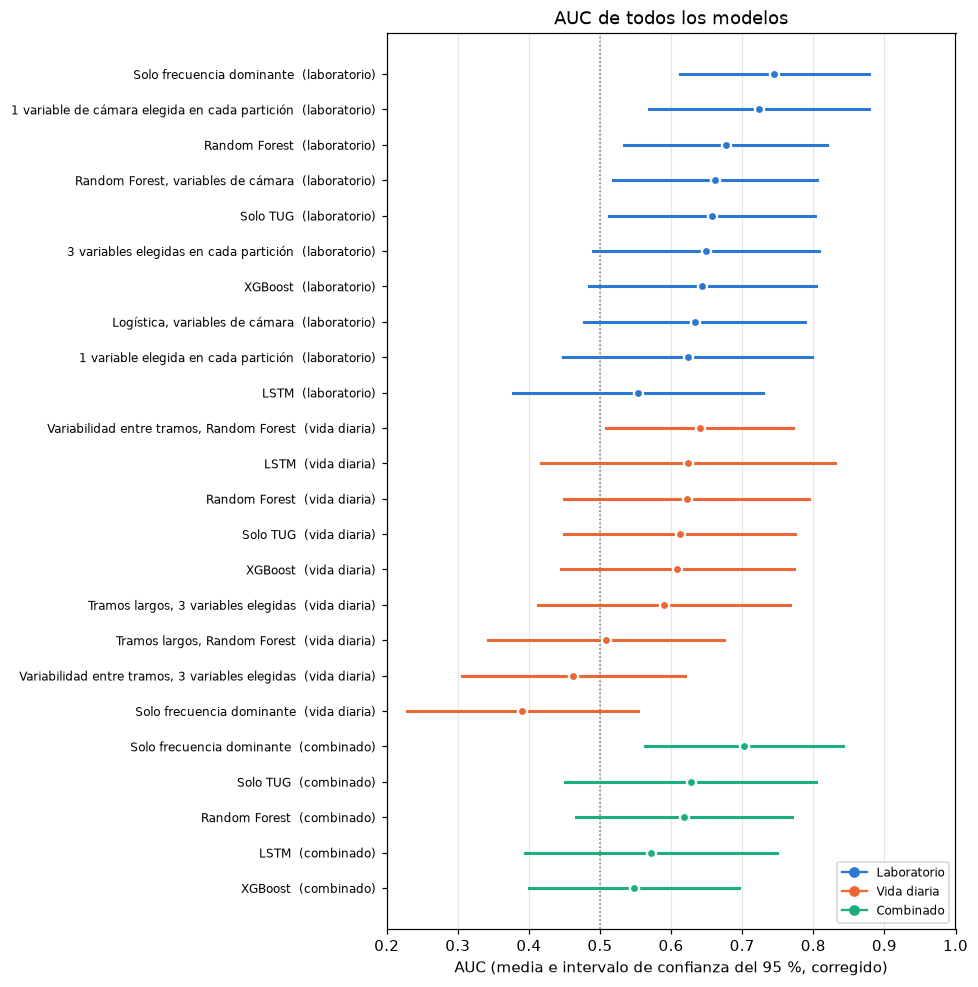

In [8]:
# Intervalo de confianza del AUC de cada modelo (sin la referencia "Sin modelo", que siempre vale 0,5)
graf = tabla[tabla["modelo"] != "Sin modelo"].iloc[::-1].reset_index(drop=True)
fig, eje = plt.subplots(figsize=(9, 0.32 * len(graf) + 1.4))
for i, r in graf.iterrows():
    color = COLORES[r["fuente"]]
    eje.plot([r["ic_inf"], r["ic_sup"]], [i, i], color=color, lw=2)
    eje.plot(r["auc_media"], i, "o", color=color, ms=6, mec="white", mew=1.5)
eje.set_yticks(range(len(graf)), [f"{m}  ({NOMBRE_FUENTE[f].lower()})" for f, m in zip(graf["fuente"], graf["modelo"])],
               fontsize=8)
eje.axvline(0.5, color="#777777", ls=":", lw=1)
eje.set(xlabel="AUC (media e intervalo de confianza del 95 %, corregido)", xlim=(0.2, 1.0),
        title="AUC de todos los modelos")
eje.grid(axis="y", visible=False)
for f, c in COLORES.items():
    eje.plot([], [], "o-", color=c, label=NOMBRE_FUENTE[f])
eje.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURAS / "seleccion_intervalos_auc.png", dpi=150)

### 6.1 Comparación estadística dentro de cada fuente de datos

Dentro de cada fuente, cada modelo se compara con el de **mayor AUC promedio** de esa fuente, sin contar la referencia de una variable elegida en el EDA (su AUC puede estar inflado porque la variable se eligió mirando a todas las personas; igual se compara con el mejor), en las pruebas que comparten (50, o 15 si uno es la LSTM). Los valores p se corrigen con Holm dentro de cada fuente. Un p corregido ≥ 0,05 significa que, con estos datos, **no se puede decir que ese modelo sea peor que el mejor**.

In [9]:
comparaciones = []
for fuente, g in todo[todo["modelo"] != "Sin modelo"].groupby("fuente", sort=False):
    medias = g.groupby("modelo")["auc"].mean()
    mejor = medias.drop(REFERENCIA_EDA, errors="ignore").idxmax()
    filas = []
    for modelo in medias.drop(mejor).index:
        a = g[g["modelo"] == mejor].set_index("particion")["auc"]
        b = g[g["modelo"] == modelo].set_index("particion")["auc"]
        comunes = a.index.intersection(b.index)
        dif, p = prueba_t_corregida(a[comunes], b[comunes])
        filas.append({"fuente": fuente, "mejor": mejor, "modelo": modelo, "pruebas": len(comunes),
                      "diferencia_auc": dif, "p": p})
    f = pd.DataFrame(filas)
    f["p_holm"] = holm(f["p"])
    comparaciones.append(f)
comparacion = pd.concat(comparaciones, ignore_index=True)
comparacion["peor_que_el_mejor"] = np.where(comparacion["p_holm"] < ALFA, "sí", "no")
comparacion.to_csv(RESULTADOS / "comparacion_estadistica.csv", index=False)
comparacion.round(3)

,fuente,mejor,modelo,pruebas,diferencia_auc,p,p_holm,peor_que_el_mejor
0,laboratorio,1 variable de cámara elegida en cada partición,1 variable elegida en cada partición,50,0.101,0.179,1.000,no
1,laboratorio,1 variable de cámara elegida en cada partición,3 variables elegidas en cada partición,50,0.074,0.242,1.000,no
2,laboratorio,1 variable de cámara elegida en cada partición,LSTM,15,0.196,0.081,0.732,no
3,laboratorio,1 variable de cámara elegida en cada partición,"Logística, variables de cámara",50,0.091,0.157,1.000,no
4,laboratorio,1 variable de cámara elegida en cada partición,Random Forest,50,0.047,0.513,1.000,no
5,laboratorio,1 variable de cámara elegida en cada partición,"Random Forest, variables de cámara",50,0.062,0.318,1.000,no
6,laboratorio,1 variable de cámara elegida en cada partición,Solo TUG,50,0.066,0.431,1.000,no
7,laboratorio,1 variable de cámara elegida en cada partición,Solo frecuencia dominante,50,-0.022,0.602,1.000,no
8,laboratorio,1 variable de cámara elegida en cada partición,XGBoost,50,0.080,0.351,1.000,no
9,vida_diaria,"Variabilidad entre tramos, Random Forest",LSTM,15,0.006,0.967,1.000,no


## 7. Selección del modelo final

Criterios, en orden, fijados antes de ver estos resultados:

1. **Que funcione con lo que la Etapa 2 puede medir.** En la Etapa 2 la persona camina unos metros frente a una cámara: se parece a la caminata de laboratorio y no a 3 días de vida diaria, y la cámara puede medir el ritmo y los tiempos de la marcha, pero no las aceleraciones ni los giros del sensor. Saeb et al. (2017) insisten en evaluar el modelo en condiciones parecidas a las de su uso real. Por eso los **candidatos** son los modelos de laboratorio que solo usan variables medibles con cámara, y su desempeño se estima con la selección de variables dentro de cada partición.
2. **Que no sea significativamente peor** que el mejor modelo de laboratorio (p de Holm ≥ 0,05, sección 6.1).
3. **Que sea lo más simple posible:** entre los que cumplen 1 y 2, el de menos variables; si empatan, el de mayor AUC. Un modelo simple se sobreajusta menos, se explica mejor a un clínico y corre sin problemas en una Raspberry Pi.

Si ningún candidato cumple el criterio 2, se elige igual el candidato de mayor AUC y se deja escrito que paga un costo de desempeño.

In [10]:
CANDIDATOS = {  # nombre: número de variables que usa
    "1 variable de cámara elegida en cada partición": 1,
    "Logística, variables de cámara": len(VARIABLES_CAMARA),
    "Random Forest, variables de cámara": len(VARIABLES_CAMARA),
}
comp_lab = comparacion[comparacion["fuente"] == "laboratorio"].set_index("modelo")
mejor_lab = comp_lab["mejor"].iloc[0]
medias_lab = todo[todo["fuente"] == "laboratorio"].groupby("modelo")["auc"].mean()
cand = pd.DataFrame({"variables": CANDIDATOS})
cand["auc"] = medias_lab.reindex(cand.index)
cand["p_holm_vs_mejor"] = [1.0 if m == mejor_lab else comp_lab.loc[m, "p_holm"] for m in cand.index]
cand["cumple_criterio_2"] = cand["p_holm_vs_mejor"] >= ALFA
validos = cand[cand["cumple_criterio_2"]]
if len(validos):
    elegido = validos.sort_values(["variables", "auc"], ascending=[True, False]).index[0]
    motivo = (f"no es significativamente peor que el mejor modelo de laboratorio ({mejor_lab}) y es el candidato "
              f"más simple ({int(cand.loc[elegido, 'variables'])} variable(s))")
else:
    elegido = cand["auc"].idxmax()
    motivo = ("ningún candidato quedó a la altura del mejor modelo; se elige el de mayor AUC, sabiendo que paga "
              "un costo de desempeño")
print(f"Mejor modelo de laboratorio (cualquier variable): {mejor_lab} (AUC {medias_lab[mejor_lab]:.3f})")
print(f"Modelo seleccionado: {elegido} -> {motivo}.")
cand.round(3)

Mejor modelo de laboratorio (cualquier variable): 1 variable de cámara elegida en cada partición (AUC 0.724)
Modelo seleccionado: 1 variable de cámara elegida en cada partición -> no es significativamente peor que el mejor modelo de laboratorio (1 variable de cámara elegida en cada partición) y es el candidato más simple (1 variable(s)).


,variables,auc,p_holm_vs_mejor,cumple_criterio_2
1 variable de cámara elegida en cada partición,1,0.724,1.0,True
"Logística, variables de cámara",9,0.633,1.0,True
"Random Forest, variables de cámara",9,0.662,1.0,True


### 7.1 Modelo final y punto de operación

El modelo elegido se entrena con **todas** las personas de laboratorio. Si es el de una variable, se usa la variable que el procedimiento eligió más veces dentro de las 50 particiones (así la elección también salió de la validación).

El umbral de 0,5 no tiene por qué ser el adecuado: para **tamizaje** importa más detectar a quien cae (sensibilidad) que evitar falsas alarmas. Por eso se calcula el umbral que da una sensibilidad de al menos 80 %, con predicciones de validación cruzada (cada persona es clasificada por un modelo que no la vio), y se informa la especificidad que se obtiene con él.

Umbral para sensibilidad ≥ 80%: 0.399 (mediana de 10 repeticiones)
Especificidad con ese umbral: 0.47 ± 0.05


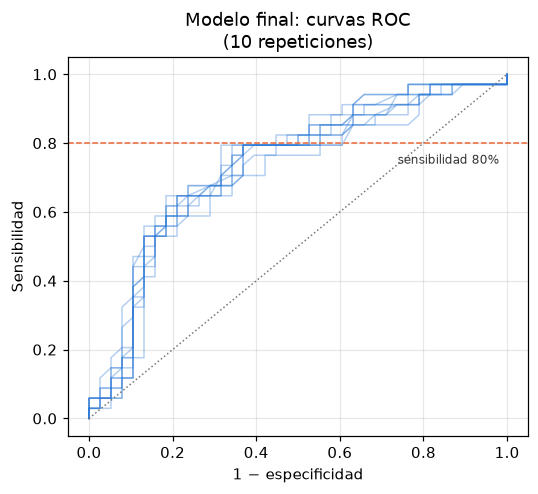

In [11]:
if elegido.startswith("1 variable de cámara"):
    VARIABLES_FINAL = [conteos[elegido].index[0]]
    modelo_final = logistica()
elif elegido.startswith("Logística"):
    VARIABLES_FINAL = VARIABLES_CAMARA
    modelo_final = logistica()
else:
    VARIABLES_FINAL = VARIABLES_CAMARA
    modelo_final = bosque()
X_final = camara[VARIABLES_FINAL]

# Probabilidades fuera de la muestra, repitiendo 10 veces la validación de 5 partes
umbrales, especificidades, rocs = [], [], []
for rep in range(N_REPETICIONES):
    cv = StratifiedKFold(n_splits=N_PARTICIONES, shuffle=True, random_state=SEMILLA + rep)
    prob = cross_val_predict(modelo_final, X_final, y_lab, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, u = roc_curve(y_lab, prob)
    i = np.argmax(tpr >= SENSIBILIDAD_OBJETIVO)           # primer umbral que alcanza la sensibilidad objetivo
    umbrales.append(u[i])
    especificidades.append(1 - fpr[i])
    rocs.append((fpr, tpr))
UMBRAL = float(np.median(umbrales))
print(f"Umbral para sensibilidad ≥ {SENSIBILIDAD_OBJETIVO:.0%}: {UMBRAL:.3f} (mediana de {N_REPETICIONES} repeticiones)")
print(f"Especificidad con ese umbral: {np.mean(especificidades):.2f} ± {np.std(especificidades):.2f}")

modelo_final.fit(X_final, y_lab)

fig, eje = plt.subplots(figsize=(5, 4.6))
for fpr, tpr in rocs:
    eje.plot(fpr, tpr, color="#2a78d6", alpha=0.35, lw=1)
eje.plot([0, 1], [0, 1], ":", color="#777777", lw=1)
eje.axhline(SENSIBILIDAD_OBJETIVO, color="#eb6834", lw=1, ls="--")
eje.text(0.98, SENSIBILIDAD_OBJETIVO - 0.06, f"sensibilidad {SENSIBILIDAD_OBJETIVO:.0%}", ha="right", fontsize=8,
         color="#333333")
eje.set(xlabel="1 − especificidad", ylabel="Sensibilidad", title=f"Modelo final: curvas ROC\n({N_REPETICIONES} repeticiones)")
fig.tight_layout()
fig.savefig(FIGURAS / "seleccion_roc_final.png", dpi=150)

In [12]:
fila = tabla[(tabla["fuente"] == "laboratorio") & (tabla["modelo"] == elegido)].iloc[0]
info = {
    "fecha": datetime.now().isoformat(timespec="seconds"),
    "modelo": elegido,
    "tipo": type(modelo_final[-1]).__name__,
    "variables_en_orden": list(VARIABLES_FINAL),
    "datos_de_entrenamiento": f"datos/procesados/labwalks_modelo.csv + labwalks_variables.csv ({len(lab)} personas)",
    "etiqueta": "cae (1 = cae, 0 = no cae)",
    "umbral_tamizaje": round(UMBRAL, 4),
    "sensibilidad_objetivo": SENSIBILIDAD_OBJETIVO,
    "especificidad_con_umbral": round(float(np.mean(especificidades)), 3),
    "validacion": {m: fila[m] for m in METRICAS} | {"auc_ic95": fila["auc_ic95"], "pruebas": int(fila["pruebas"])},
    "criterios": ["variables medibles con cámara, en condiciones de laboratorio",
                  "no significativamente peor que el mejor modelo de laboratorio (prueba t corregida + Holm)",
                  "el más simple de los que cumplen"],
    "motivo": motivo,
    "mejor_modelo_laboratorio": {"modelo": mejor_lab, "auc": round(float(medias_lab[mejor_lab]), 3)},
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "numpy": np.__version__, "pandas": pd.__version__},
}
joblib.dump(modelo_final, MODELOS / "modelo_final.joblib")
(MODELOS / "info_modelo_final.json").write_text(json.dumps(info, indent=2, ensure_ascii=False), encoding="utf-8")
if hasattr(modelo_final[-1], "coef_"):
    coef = pd.Series(modelo_final[-1].coef_[0], index=VARIABLES_FINAL)
    print("Coeficientes (variables estandarizadas; positivo = más riesgo):")
    print(coef.round(3).to_string())
print("\nGuardado: modelos/modelo_final.joblib y modelos/info_modelo_final.json")

# Prueba: cargarlo y usarlo como se hará en la Etapa 2
cargado = joblib.load(MODELOS / "modelo_final.joblib")
ejemplo = camara.sample(3, random_state=SEMILLA)
prob = cargado.predict_proba(ejemplo[info["variables_en_orden"]])[:, 1]
pd.DataFrame({"registro": ejemplo["registro"], "grupo real": lab.loc[ejemplo.index, "grupo"],
              "probabilidad de caer": prob.round(2), "riesgo": np.where(prob >= UMBRAL, "alto", "bajo")})

Coeficientes (variables estandarizadas; positivo = más riesgo):
frec_dominante_hz   -0.872

Guardado: modelos/modelo_final.joblib y modelos/info_modelo_final.json


,registro,grupo real,probabilidad de caer,riesgo
4,co005_base,No cae,0.79,alto
62,fl030_base,Cae,0.38,bajo
18,co020_base,No cae,0.50,alto


## 8. Resumen para el informe

In [13]:
fmt = lambda x, d=2: f"{x:.{d}f}".replace(".", ",")
r_lab = tabla[tabla["fuente"] == "laboratorio"].set_index("modelo")
print(f"* Se compararon {todo.groupby(['fuente', 'modelo']).ngroups} combinaciones de modelo y fuente de datos "
      f"con validación cruzada estratificada repetida (prueba t corregida de Nadeau y Bengio + Holm).")
for fuente in FUENTES:
    c = comparacion[comparacion["fuente"] == fuente]
    if len(c):
        m = c["mejor"].iloc[0]
        r = tabla[(tabla["fuente"] == fuente) & (tabla["modelo"] == m)].iloc[0]
        print(f"* {NOMBRE_FUENTE[fuente]}: mejor AUC {m} ({fmt(r['auc_media'])}, IC 95 % {r['auc_ic95'].replace('.', ',')}).")
for fuente in FUENTES:
    c = comparacion[comparacion["fuente"] == fuente]
    if len(c):
        peores = c[c["peor_que_el_mejor"] == "sí"]["modelo"].tolist()
        print(f"* {NOMBRE_FUENTE[fuente]}: modelos significativamente peores que el mejor: "
              f"{', '.join(peores) if peores else 'ninguno'}.")
ref = next((m for m in REFERENCIA_EDA if m in r_lab.index), None)
if ref and "1 variable elegida en cada partición" in r_lab.index:
    print(f"* Sesgo de selección: '{ref}' (variable elegida mirando a todos) AUC "
          f"{fmt(r_lab.loc[ref, 'auc_media'])}; eligiendo la variable dentro de cada partición "
          f"{fmt(r_lab.loc['1 variable elegida en cada partición', 'auc_media'])}.")
print(f"* Modelo seleccionado para la Etapa 2: {elegido} -> {', '.join(VARIABLES_FINAL)}; AUC "
      f"{fmt(r_lab.loc[elegido, 'auc_media'])} (IC 95 % {r_lab.loc[elegido, 'auc_ic95'].replace('.', ',')}). Motivo: {motivo}.")
print(f"* Umbral de tamizaje {fmt(UMBRAL, 3)}: sensibilidad ≥ {SENSIBILIDAD_OBJETIVO:.0%} con especificidad "
      f"{fmt(np.mean(especificidades))} ± {fmt(np.std(especificidades))}.")

* Se compararon 27 combinaciones de modelo y fuente de datos con validación cruzada estratificada repetida (prueba t corregida de Nadeau y Bengio + Holm).
* Laboratorio: mejor AUC 1 variable de cámara elegida en cada partición (0,72, IC 95 % [0,57; 0,88]).
* Vida diaria: mejor AUC Variabilidad entre tramos, Random Forest (0,64, IC 95 % [0,51; 0,77]).
* Combinado: mejor AUC Solo TUG (0,63, IC 95 % [0,45; 0,80]).
* Laboratorio: modelos significativamente peores que el mejor: ninguno.
* Vida diaria: modelos significativamente peores que el mejor: ninguno.
* Combinado: modelos significativamente peores que el mejor: ninguno.
* Sesgo de selección: 'Solo frecuencia dominante' (variable elegida mirando a todos) AUC 0,75; eligiendo la variable dentro de cada partición 0,62.
* Modelo seleccionado para la Etapa 2: 1 variable de cámara elegida en cada partición -> frec_dominante_hz; AUC 0,72 (IC 95 % [0,57; 0,88]). Motivo: no es significativamente peor que el mejor modelo de laboratorio (1 variab

**Interpretación**

* **¿Hay algún modelo claramente mejor que los demás?** No. Ningún modelo resultó significativamente peor que el mejor de su fuente de datos después de la corrección de Holm. Los intervalos de confianza del AUC miden alrededor de ±0,15 y se superponen casi por completo: por ejemplo, el mejor modelo de laboratorio (una variable de cámara, AUC 0,72) no se diferencia de Random Forest (0,68; p = 0,51) ni de XGBoost (0,64; p = 0,35). Con unas 70 personas, la validación cruzada no alcanza para distinguir modelos cuyo AUC difiere en menos de unos 0,15. Por eso la selección del modelo final se basó en los criterios fijados de antemano (que se pueda medir con cámara, que no sea peor que el mejor y que sea el más simple) y no solo en el AUC.

* **¿Cuánto bajó la frecuencia dominante al elegirla de forma honesta?** En la sub-etapa 1.3 obtuvo un AUC de 0,75, pero esa variable se había elegido en el EDA mirando a todas las personas. Cuando el modelo elige la variable solo con las personas de entrenamiento de cada partición, el AUC baja a 0,62 si puede elegir entre las 14 variables (elige la frecuencia dominante solo en 28 de 50 particiones) y a 0,72 si elige entre las variables medibles con cámara (la elige en 46 de 50). La frecuencia dominante sí es la variable más informativa, pero el 0,75 era algo optimista: la estimación honesta está entre 0,62 y 0,72.

* **¿Alguna variante de vida diaria mejoró?** No. La mejor fue la variabilidad entre tramos con Random Forest (AUC 0,64), casi igual al Random Forest original de vida diaria (0,62) y sin diferencia significativa. Usar solo los tramos largos no ayudó (0,51 a 0,59). El resultado negativo de la extensión con registros de 3 días se mantiene: más marcha por persona no mejoró la clasificación, porque el número de personas sigue siendo el mismo.

* **¿Qué especificidad se paga para detectar al 80 % de quienes caen?** Con el umbral de 0,40, el modelo detecta al 80 % de quienes caen, pero su especificidad baja a 0,47 ± 0,05: daría una falsa alarma a aproximadamente la mitad de quienes no caen. Para un diagnóstico no sería aceptable, pero para un tamizaje inicial puede servir como primer filtro, para decidir a quién conviene hacerle una evaluación clínica completa. Hay que recordar además que las etiquetas son retrospectivas (caídas del año anterior), por lo que el modelo reconoce a quienes ya cayeron y no predice caídas futuras.

**Referencias de este notebook:** C. Nadeau y Y. Bengio, "Inference for the generalization error," *Mach. Learn.*, vol. 52, pp. 239–281, 2003. R. R. Bouckaert y E. Frank, "Evaluating the replicability of significance tests for comparing learning algorithms," en *PAKDD*, 2004, pp. 3–12. S. Saeb *et al.*, *GigaScience*, vol. 6, no. 5, 2017.